# Real Estate Price Prediction

**Dataset -** Ames Housing Dataset

This notebook predicts house sale prices using property features like size, quality, location and amenities. I cleaned and prepared the raw data, trained two models (Linear Regression and Random Forest) and compared how well each one predicted price. The results were then exported for a Power BI dashboard.

**Tools:** Python (pandas, scikit-learn, matplotlib, seaborn)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the data

Loaded the training and test datasets and took a first look at their size and structure before doing any cleaning.

In [4]:
train = pd.read_csv('../data/train_data.csv')

In [5]:
test = pd.read_csv('../data/test_data.csv')

In [6]:
print(train.shape, test.shape)

(1460, 81) (1459, 80)


In [7]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Checking data quality

Checked column types, counted missing values and looked at how the target variable (`SalePrice`) was distributed. This helped decide what cleaning was 
needed before modeling.

In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [10]:
train.isnull().sum().sort_values(ascending=False).head(20)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Id                 0
dtype: int64

## Missing values and correlation check

Listed every column that had missing values and checked which numeric features were most strongly correlated with `SalePrice`. This gave an early sense of which features were likely to matter most.

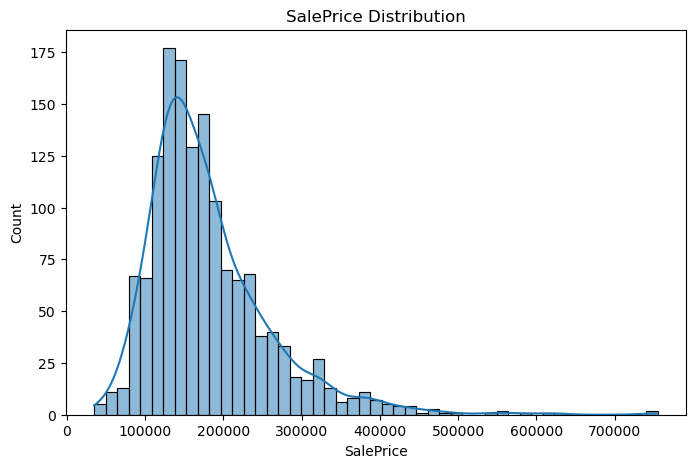

Skewness: 1.8828757597682129


In [12]:
plt.figure(figsize=(8,5))
sns.histplot(train['SalePrice'], kde=True)
plt.title('SalePrice Distribution')
plt.show()

print("Skewness:", train['SalePrice'].skew())

In [13]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
Electrical         1
dtype: int64


In [14]:
numeric_cols = train.select_dtypes(include=[np.number])
corr = numeric_cols.corr()['SalePrice'].sort_values(ascending=False)
print(corr.head(15))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64


## Handling missing values

Different columns had missing values for different reasons so each group was handled differently:
- Some columns were missing because the house simply didn't have that feature (e.g. no pool, no garage). These were filled with `"None"` or `0`.
- `LotFrontage` was genuinely missing data so it was filled using the median value for each neighborhood.
- A few columns had only a handful of missing values so those were filled with the mode.

The final check confirmed there were no missing values left in the dataset.

In [16]:
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType']

for col in none_cols:
    train[col] = train[col].fillna('None')

In [17]:
zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars',
             'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
             'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']

for col in zero_cols:
    train[col] = train[col].fillna(0)

In [18]:
train['LotFrontage'] = train.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

In [19]:
mode_cols = ['Electrical', 'MSZoning', 'Utilities', 'Exterior1st',
             'Exterior2nd', 'KitchenQual', 'Functional', 'SaleType']

for col in mode_cols:
    if col in train.columns:
        train[col] = train[col].fillna(train[col].mode()[0])

In [20]:
train.isnull().sum().sum() 

0

## Encoding quality and rating columns

Several columns described quality or condition using labels like Poor, Fair, Typical, Good, Excellent. These had a natural order so instead of one-hot 
encoding them they were mapped to numbers (e.g. Poor = 1, Excellent = 5). This kept the "better than" relationship intact for the model. The same approach was used for a few other ordered columns like `Functional`, `LandSlope`, and `PavedDrive`. A final check confirmed none of the mappings had accidentally created missing values.

In [22]:
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}

ordinal_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
                 'HeatingQC', 'KitchenQual', 'FireplaceQu',
                 'GarageQual', 'GarageCond', 'PoolQC']

for col in ordinal_cols:
    train[col] = train[col].map(qual_map)

In [23]:
train['BsmtExposure'] = train['BsmtExposure'].map(
    {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}
)

In [24]:
bsmt_fin_map = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
train['BsmtFinType1'] = train['BsmtFinType1'].map(bsmt_fin_map)
train['BsmtFinType2'] = train['BsmtFinType2'].map(bsmt_fin_map)

In [25]:
train['GarageFinish'] = train['GarageFinish'].map(
    {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}
)

In [26]:
train['Fence'] = train['Fence'].map(
    {'None': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4}
)

In [27]:
train['Functional'] = train['Functional'].map(
    {'Sal':0,'Sev':1,'Maj2':2,'Maj1':3,'Mod':4,'Min2':5,'Min1':6,'Typ':7}
)

In [28]:
train['LandSlope'] = train['LandSlope'].map({'Sev':0,'Mod':1,'Gtl':2})

In [29]:
train['PavedDrive'] = train['PavedDrive'].map({'N':0,'P':1,'Y':2})

In [30]:
train[ordinal_cols + ['BsmtExposure','BsmtFinType1','BsmtFinType2','GarageFinish','Fence','Functional','LandSlope','PavedDrive']].isnull().sum()

ExterQual       0
ExterCond       0
BsmtQual        0
BsmtCond        0
HeatingQC       0
KitchenQual     0
FireplaceQu     0
GarageQual      0
GarageCond      0
PoolQC          0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
GarageFinish    0
Fence           0
Functional      0
LandSlope       0
PavedDrive      0
dtype: int64

## Encoding remaining categorical columns

The columns that were left (like `Neighborhood`, `SaleCondition`, `RoofStyle`) didn't have a natural order so they were one-hot encoded instead turned into separate True/False columns for each category. Before that `Utilities` was dropped since almost every row had the same value so it wouldn't have helped the model learn anything.

In [32]:
categorical_cols = train.select_dtypes(include='object').columns.tolist()
print(categorical_cols)  # sanity check before encoding

['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir', 'Electrical', 'GarageType', 'MiscFeature', 'SaleType', 'SaleCondition']


In [33]:
train['Utilities'].value_counts()

Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64

In [34]:
train = train.drop(columns=['Utilities'])

In [35]:
categorical_cols = train.select_dtypes(include='object').columns.tolist()
train_encoded = pd.get_dummies(train, columns=categorical_cols, drop_first=True)
print(train_encoded.shape)

(1460, 205)


## Transforming the target variable

`SalePrice` was right-skewed (a few very expensive houses pulled the distribution long) which can hurt model performance. Applying a log transformation made the distribution closer to normal which linear models handled better.

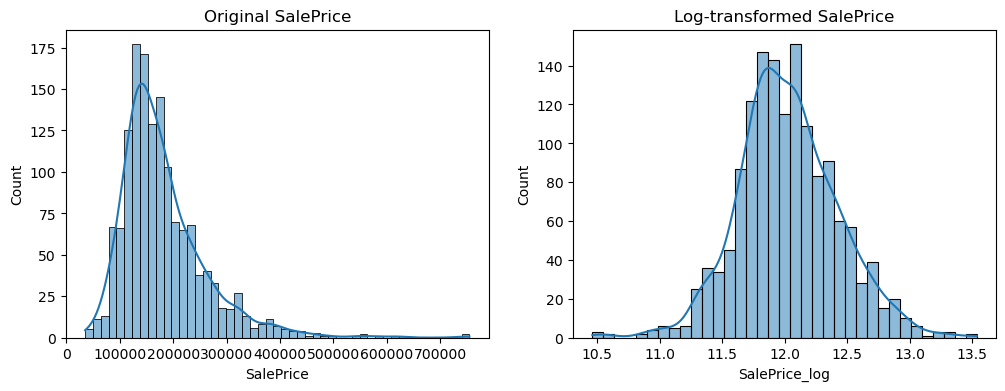

In [37]:
train_encoded['SalePrice_log'] = np.log1p(train_encoded['SalePrice'])

# quick before/after comparison
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(train_encoded['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('Original SalePrice')
sns.histplot(train_encoded['SalePrice_log'], kde=True, ax=axes[1])
axes[1].set_title('Log-transformed SalePrice')
plt.show()

## Creating new features

A few extra features were built from existing columns since they tend to be strong price signals: total square footage (`TotalSF`), house age, time since last remodel and total number of bathrooms (combining full and half baths).

In [39]:
train_encoded['TotalSF'] = train_encoded['TotalBsmtSF'] + train_encoded['1stFlrSF'] + train_encoded['2ndFlrSF']
train_encoded['HouseAge'] = train_encoded['YrSold'] - train_encoded['YearBuilt']
train_encoded['RemodAge'] = train_encoded['YrSold'] - train_encoded['YearRemodAdd']
train_encoded['TotalBath'] = (train_encoded['FullBath'] + 0.5*train_encoded['HalfBath'] +
                               train_encoded['BsmtFullBath'] + 0.5*train_encoded['BsmtHalfBath'])

## Splitting the data

Split the data into a training set (80%) and a test set (20%). The model learned only from the training set and the test set was used later to check how well it performed on data it hadn't seen.

In [41]:
from sklearn.model_selection import train_test_split

X = train_encoded.drop(columns=['Id', 'SalePrice', 'SalePrice_log'])
y = train_encoded['SalePrice_log']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(1168, 207) (292, 207)


## Model 1: Linear Regression

Trained a Linear Regression model as a baseline. It assumes a straight-line 
relationship between the features and price which made it simple and easy to interpret but limited when relationships were more complex.

In [43]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print(f"Linear Regression -> RMSE: {rmse_lr:.4f}, R²: {r2_lr:.4f}")

Linear Regression -> RMSE: 0.2034, R²: 0.7783


## Model 2: Random Forest

Trained a Random Forest model which builds many decision trees and averages their predictions. It captured non-linear patterns and interactions between 
features that Linear Regression couldn't which made it more accurate on this data overall.

In [45]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest -> RMSE: {rmse_rf:.4f}, R²: {r2_rf:.4f}")

Random Forest -> RMSE: 0.1463, R²: 0.8853


## Checking prediction errors

Plotted the Linear Regression model's residuals (the difference between actual and predicted values) to check if the errors were random and evenly spread a sign of a healthy model. One noticeable outlier was then inspected directly to understand why the model got that particular house so wrong.

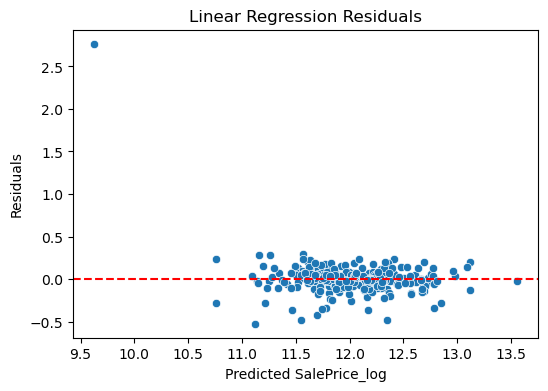

In [47]:
residuals = y_test - y_pred_lr
plt.figure(figsize=(6,4))
sns.scatterplot(x=y_pred_lr, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted SalePrice_log')
plt.ylabel('Residuals')
plt.title('Linear Regression Residuals')
plt.show()

In [48]:
outlier_idx = residuals[residuals > 2].index
train.loc[outlier_idx, ['SalePrice', 'GrLivArea', 'OverallQual', 'Neighborhood']]

,SalePrice,GrLivArea,OverallQual,Neighborhood
271,241500,1363,7,ClearCr


## Which features mattered most

Used the Random Forest model to rank features by how much they influenced the predicted price. This helped explain the model's decisions not just its 
accuracy.

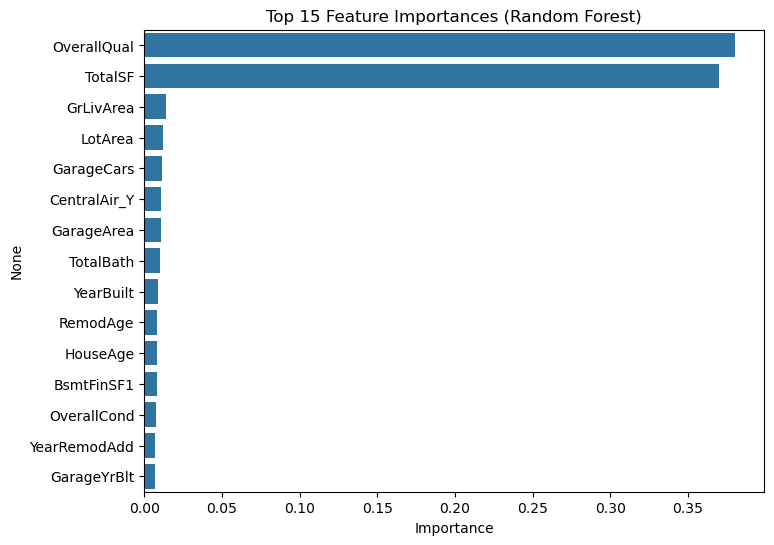

In [50]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
top_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8,6))
sns.barplot(x=top_features.values, y=top_features.index)
plt.title('Top 15 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.show()

## Comparing both models visually

Plotted actual prices against predicted prices for both models on the same chart. Points closer to the diagonal line meant more accurate predictions which made it easy to see at a glance which model tracked real prices better.

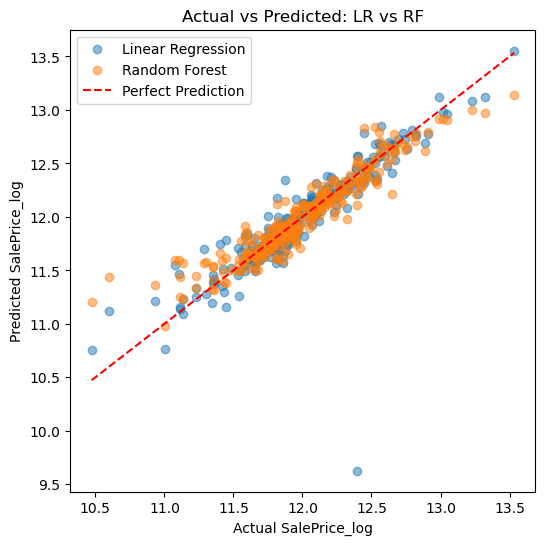

In [52]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_lr, alpha=0.5, label='Linear Regression')
plt.scatter(y_test, y_pred_rf, alpha=0.5, label='Random Forest')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Perfect Prediction')
plt.xlabel('Actual SalePrice_log')
plt.ylabel('Predicted SalePrice_log')
plt.legend()
plt.title('Actual vs Predicted: LR vs RF')
plt.show()

## Converting errors back to real dollars

The models were trained on log-transformed prices so their error scores were in log units which weren't intuitive. Converting predictions back to normal dollar values made the error size easier to understand for example "the model was typically off by about $X."

In [54]:
y_test_dollars = np.expm1(y_test)
y_pred_rf_dollars = np.expm1(y_pred_rf)
y_pred_lr_dollars = np.expm1(y_pred_lr)

rmse_rf_dollars = np.sqrt(mean_squared_error(y_test_dollars, y_pred_rf_dollars))
rmse_lr_dollars = np.sqrt(mean_squared_error(y_test_dollars, y_pred_lr_dollars))

print(f"RF RMSE in $: {rmse_rf_dollars:,.0f}")
print(f"LR RMSE in $: {rmse_lr_dollars:,.0f}")

RF RMSE in $: 30,158
LR RMSE in $: 25,933


## Comparing errors by price and neighborhood and exporting results

Looked more closely at where each model performed well or poorly specifically whether errors were larger for higher-priced homes and how many homes in the dataset were actually in that high price range. The results (actual prices, predicted prices and errors for both models) were then saved as CSV files along with feature importance scores so they could be used to build a dashboard in Power BI.

In [56]:
results = X_test.copy()
results['SalePrice_actual'] = y_test_dollars.values
results['SalePrice_predicted_RF'] = y_pred_rf_dollars
results['SalePrice_predicted_LR'] = y_pred_lr_dollars
results['Neighborhood'] = train.loc[X_test.index, 'Neighborhood'].values  # bring back original (non-encoded) neighborhood name

results.to_csv('../outputs/model_results_for_powerbi.csv', index=False)

In [57]:
errors_rf = np.abs(y_test_dollars - y_pred_rf_dollars)
errors_lr = np.abs(y_test_dollars - y_pred_lr_dollars)

comparison = pd.DataFrame({
    'Actual': y_test_dollars,
    'RF_error': errors_rf,
    'LR_error': errors_lr
}).sort_values('Actual', ascending=False)

comparison.head(10)

,Actual,RF_error,LR_error
691,755000.0,247891.202739,15832.950663
898,611657.0,182091.157999,110907.188975
1046,556581.0,114177.607093,73339.498541
1243,465000.0,63571.443312,40303.136247
591,451950.0,46720.212650,16397.838064
58,438780.0,30742.270178,58659.313529
231,403000.0,44297.010619,51082.968232
774,395000.0,92376.238203,70940.514753
585,369900.0,12234.567429,23616.616228
1228,367294.0,35023.927329,13265.105867


In [58]:
train_encoded['SalePrice'].describe()
(train_encoded['SalePrice'] > 500000).sum()

9

In [59]:
results = X_test.copy()
results['SalePrice_actual'] = y_test_dollars.values
results['SalePrice_predicted_RF'] = y_pred_rf_dollars
results['SalePrice_predicted_LR'] = y_pred_lr_dollars
results['RF_error'] = errors_rf.values
results['LR_error'] = errors_lr.values
results['Neighborhood'] = train.loc[X_test.index, 'Neighborhood'].values

results.to_csv('../outputs/model_results_for_powerbi.csv', index=False)
print(results.shape)
print(results[['SalePrice_actual','SalePrice_predicted_RF','SalePrice_predicted_LR','Neighborhood']].head())

(292, 213)
      SalePrice_actual  SalePrice_predicted_RF  SalePrice_predicted_LR  \
892           154500.0           140181.202063           150317.454278   
1105          325000.0           326579.925173           337192.845940   
413           115000.0           112920.034964           101214.552236   
522           159000.0           148627.245963           165129.886795   
1036          315500.0           310784.022208           299436.464251   

     Neighborhood  
892        Sawyer  
1105      NoRidge  
413       OldTown  
522       BrkSide  
1036       Timber  


In [60]:
importances_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

importances_df.to_csv('../outputs/feature_importances.csv', index=False)
importances_df.head(15)

,Feature,Importance
4,OverallQual,0.380053
203,TotalSF,0.369844
24,GrLivArea,0.014132
2,LotArea,0.011832
38,GarageCars,0.011235
175,CentralAir_Y,0.011057
39,GarageArea,0.010625
206,TotalBath,0.010132
6,YearBuilt,0.009066
205,RemodAge,0.008533


## Saving the trained models

Saved both trained models to disk so they could be reused later without retraining useful if I wanted to make new predictions or deploy the model down 
the line.

In [62]:
import joblib
joblib.dump(rf, '../models/random_forest_model.pkl')
joblib.dump(lr, '../models/linear_regression_model.pkl')

['linear_regression_model.pkl']

## Summary & key findings

- Random Forest outperformed Linear Regression on overall fit (R² 0.885 vs 0.778) and had lower error on the log-transformed price scale.
- On raw dollar error Linear Regression actually did slightly better (about $25,933 RMSE vs about $30,158 for Random Forest) because Random Forest struggled specifically with the small number of high-priced homes (only 9 out of 1,460 were above $500K). It couldn't extrapolate well beyond what it had seen enough examples of.
- `OverallQual` and `TotalSF` were by far the two strongest predictors of price consistent with what real-world intuition would suggest.
- This showed that no single model wins on every metric. The right choice depends on which type of error matters more for the use case.